# Task 5 — Time-Series Forecasting with ARIMA

**Objective:** inspect daily demand, decompose trend/seasonality/residuals, test stationarity with ADF, use differencing when appropriate, select an ARIMA configuration on a chronological holdout, evaluate with MAPE/RMSE, and forecast the next 30 days.

**Dataset note:** the supplied file contains only 30 observations. Results and future projections are educational demonstrations with substantial uncertainty.

## 1. Imports and load data

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

DATA_PATH = Path("../data/raw/daily-demand-series.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/raw/daily-demand-series.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place daily-demand-series.csv in data/raw/.")

df = pd.read_csv(DATA_PATH, parse_dates=["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
series = df.set_index("date")["demand"].asfreq("D")
if series.isna().any():
    print("Missing demand values found; interpolating for this demonstration.")
    series = series.interpolate()
print("Rows:", len(series))
print("Date range:", series.index.min().date(), "to", series.index.max().date())
display(df.head())
display(df.describe(include="all"))

Rows: 30
Date range: 2026-06-01 to 2026-06-30


,date,demand,marketing_event,holiday
0,2026-06-01,118,0,0
1,2026-06-02,121,0,0
2,2026-06-03,125,0,0
3,2026-06-04,123,0,0
4,2026-06-05,137,1,0


,date,demand,marketing_event,holiday
count,30,30.000000,30.000000,30.000000
mean,2026-06-15 12:00:00,142.100000,0.266667,0.133333
min,2026-06-01 00:00:00,118.000000,0.000000,0.000000
25%,2026-06-08 06:00:00,132.500000,0.000000,0.000000
50%,2026-06-15 12:00:00,142.000000,0.000000,0.000000
75%,2026-06-22 18:00:00,150.250000,0.750000,0.000000
max,2026-06-30 00:00:00,174.000000,1.000000,1.000000
std,NaN,13.839848,0.449776,0.345746


## 2. Plot historical demand

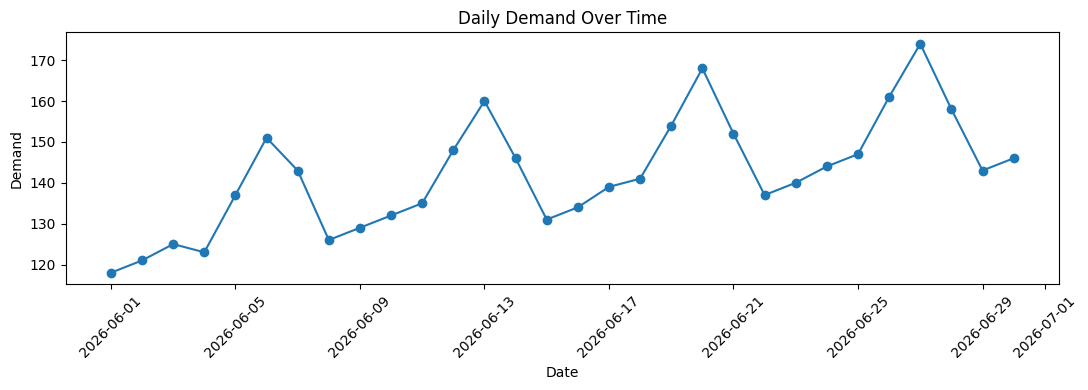

In [2]:
plt.figure(figsize=(11, 4))
plt.plot(series.index, series.values, marker="o")
plt.title("Daily Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Decompose trend, seasonal, and residual components

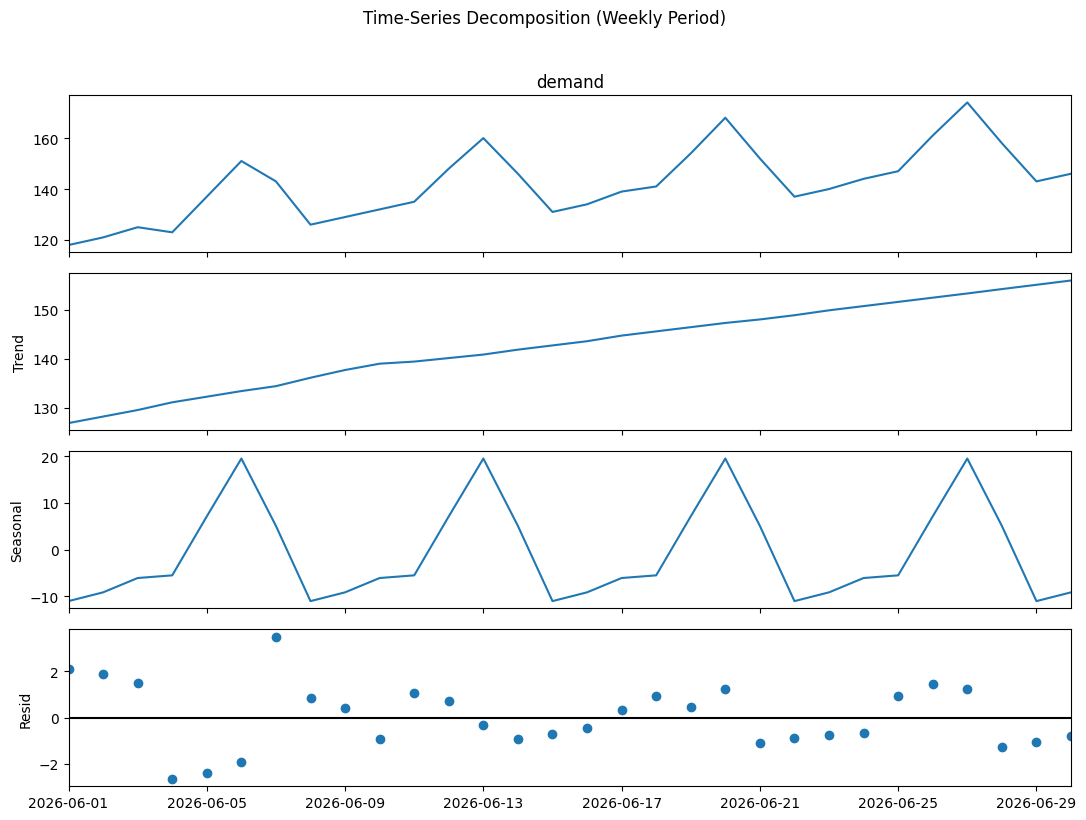

In [3]:
# A period of 7 checks for a weekly pattern. With only 30 observations,
# the decomposition is illustrative and should be interpreted cautiously.
decomp = seasonal_decompose(series, model="additive", period=7, extrapolate_trend="freq")
fig = decomp.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Time-Series Decomposition (Weekly Period)", y=1.02)
plt.tight_layout()
plt.show()

## 4. ADF test for stationarity

In [4]:
def run_adf(x, label):
    result = adfuller(pd.Series(x).dropna(), autolag="AIC")
    print(f"{label}: ADF statistic={result[0]:.4f}, p-value={result[1]:.4f}, lags={result[2]}")
    if result[1] < 0.05:
        print("Interpretation: reject the unit-root null at 5%; evidence supports stationarity.")
    else:
        print("Interpretation: do not reject the unit-root null at 5%; stationarity is not established.")
    return result[1]

adf_p_original = run_adf(series, "Original demand")
diff1 = series.diff().dropna()
adf_p_diff1 = run_adf(diff1, "First-differenced demand")
d = 0 if adf_p_original < 0.05 else 1
print("Differencing order selected for the simple ARIMA search:", d)

Original demand: ADF statistic=-0.9039, p-value=0.7867, lags=7
Interpretation: do not reject the unit-root null at 5%; stationarity is not established.
First-differenced demand: ADF statistic=-2.2336, p-value=0.1943, lags=6
Interpretation: do not reject the unit-root null at 5%; stationarity is not established.
Differencing order selected for the simple ARIMA search: 1


## 5. Chronological train/test split and ARIMA order selection

In [5]:
# Keep the last 7 days as a test set; never randomly shuffle time-series data.
test_size = 7
train, test = series.iloc[:-test_size], series.iloc[-test_size:]
print("Train observations:", len(train), "| Test observations:", len(test))

def safe_mape(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    nonzero = actual != 0
    return float(np.mean(np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])) * 100)

results = []
# Small, intentionally constrained search suitable for a tiny dataset.
for p in range(0, 3):
    for q in range(0, 3):
        try:
            fit = ARIMA(train, order=(p, d, q)).fit()
            pred = fit.forecast(steps=len(test))
            rmse = float(np.sqrt(mean_squared_error(test, pred)))
            mape = safe_mape(test, pred)
            results.append({"order": (p, d, q), "AIC": float(fit.aic), "RMSE": rmse, "MAPE_percent": mape})
        except Exception as e:
            print(f"Skipped ARIMA({p},{d},{q}): {e}")

results_df = pd.DataFrame(results).sort_values(["RMSE", "AIC"]).reset_index(drop=True)
display(results_df)
best_order = results_df.loc[0, "order"]
print("Selected order based on holdout RMSE (AIC breaks ties):", best_order)

Train observations: 23 | Test observations: 7


,order,AIC,RMSE,MAPE_percent
0,"(2, 1, 2)",161.154047,12.949515,5.423465
1,"(0, 1, 2)",161.222468,13.636285,5.559358
2,"(2, 1, 0)",161.729235,13.941643,6.607978
3,"(1, 1, 2)",161.491617,14.717165,6.272975
4,"(0, 1, 1)",162.584534,15.157210,6.600936
5,"(2, 1, 1)",161.414090,15.386048,6.484130
6,"(1, 1, 1)",164.240391,15.756728,7.125320
7,"(1, 1, 0)",168.761754,16.385135,7.709583
8,"(0, 1, 0)",167.916471,17.033580,8.246184


Selected order based on holdout RMSE (AIC breaks ties): (2, 1, 2)


## 6. Evaluate selected model on holdout data

Holdout RMSE: 12.950
Holdout MAPE: 5.42%


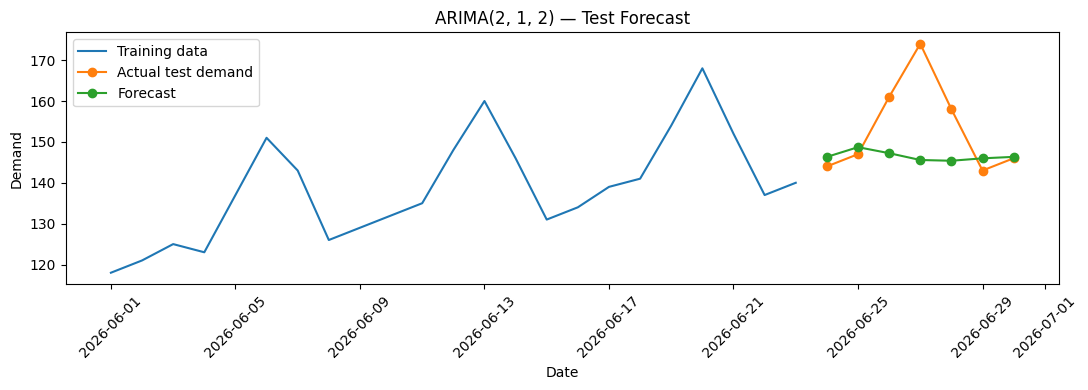

In [6]:
best_fit_train = ARIMA(train, order=best_order).fit()
test_forecast = best_fit_train.forecast(steps=len(test))
rmse = float(np.sqrt(mean_squared_error(test, test_forecast)))
mape = safe_mape(test, test_forecast)
print(f"Holdout RMSE: {rmse:.3f}")
print(f"Holdout MAPE: {mape:.2f}%")

plt.figure(figsize=(11, 4))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, marker="o", label="Actual test demand")
plt.plot(test.index, test_forecast, marker="o", label="Forecast")
plt.title(f"ARIMA{best_order} — Test Forecast")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Fit final model and forecast the next 30 days

,date,forecast_demand,lower_95,upper_95
0,2026-07-01,152.329817,138.278194,166.381440
1,2026-07-02,154.736274,130.228038,179.244510
2,2026-07-03,153.244235,127.001053,179.487418
3,2026-07-04,151.536718,125.231235,177.842202
4,2026-07-05,151.348210,124.907676,177.788745
5,2026-07-06,151.968933,124.805326,179.132541
6,2026-07-07,152.341387,124.147169,180.535604
7,2026-07-08,152.259724,123.279602,181.239846
8,2026-07-09,152.066161,122.521403,181.610918
9,2026-07-10,152.008418,121.928335,182.088500


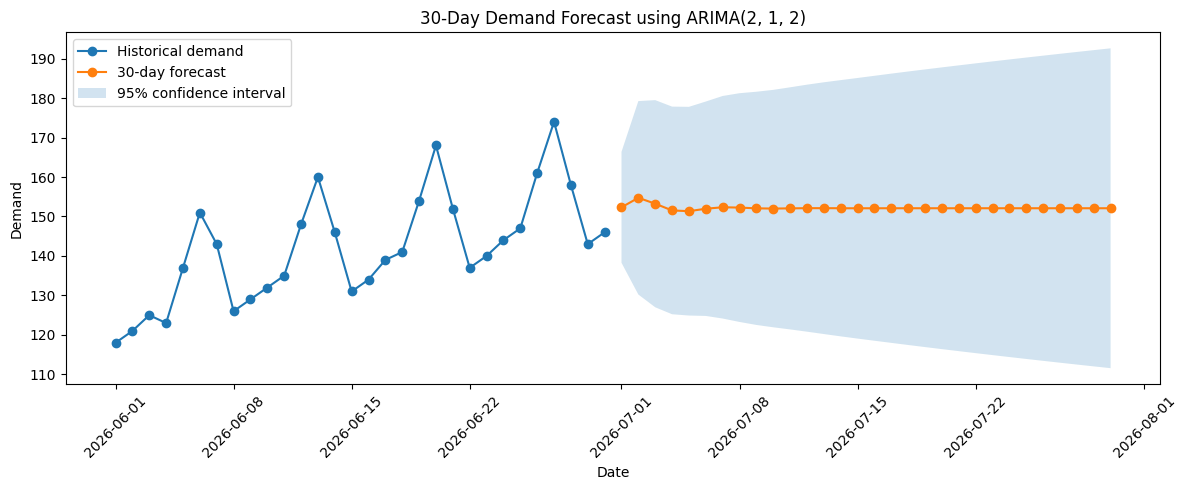

In [7]:
final_fit = ARIMA(series, order=best_order).fit()
forecast_result = final_fit.get_forecast(steps=30)
forecast_mean = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int()

future_dates = pd.date_range(series.index[-1] + pd.Timedelta(days=1), periods=30, freq="D")
forecast_mean.index = future_dates
forecast_ci.index = future_dates

forecast_df = pd.DataFrame({
    "date": future_dates,
    "forecast_demand": forecast_mean.values,
    "lower_95": forecast_ci.iloc[:, 0].values,
    "upper_95": forecast_ci.iloc[:, 1].values
})
display(forecast_df.head(10))

plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, marker="o", label="Historical demand")
plt.plot(forecast_df["date"], forecast_df["forecast_demand"], marker="o", label="30-day forecast")
plt.fill_between(forecast_df["date"], forecast_df["lower_95"], forecast_df["upper_95"], alpha=0.2, label="95% confidence interval")
plt.title(f"30-Day Demand Forecast using ARIMA{best_order}")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 8. Findings and limitations

In [8]:
print("SUMMARY")
print(f"- Observations: {len(series)} daily records.")
print(f"- Selected ARIMA order: {best_order}.")
print(f"- Holdout RMSE: {rmse:.3f}.")
print(f"- Holdout MAPE: {mape:.2f}%.")
print(f"- Forecast horizon: {len(forecast_df)} days.")
print("- Important limitation: only 30 observations are available, so model selection and seasonal estimates are unstable.")
print("- The marketing_event and holiday columns are available in the dataset but are not used by this univariate ARIMA model.")

SUMMARY
- Observations: 30 daily records.
- Selected ARIMA order: (2, 1, 2).
- Holdout RMSE: 12.950.
- Holdout MAPE: 5.42%.
- Forecast horizon: 30 days.
- Important limitation: only 30 observations are available, so model selection and seasonal estimates are unstable.
- The marketing_event and holiday columns are available in the dataset but are not used by this univariate ARIMA model.


## 9. Conclusion (write after reviewing your outputs)

In your own words, summarize:
1. Whether the original series appeared stationary according to the ADF p-value.
2. Whether differencing was used.
3. Which ARIMA order was selected and why.
4. The test RMSE and MAPE.
5. What the 30-day forecast suggests, while clearly mentioning the limitation of having only 30 historical observations.

**Do not claim the forecast is highly reliable.** A longer historical dataset is needed to assess annual/longer seasonal patterns and produce more dependable forecasts.